# M3 – Step 1: Get to know the oracle data (disk-loading view)

Goal: understand the shape of FM(D, T) **before** choosing surrogates.
Rotor theory says FM depends mainly on how hard the disk is loaded, DL = T / A with A = πD²/4,
so this notebook checks that idea directly.
For every section: write your **prediction before running**, then your **observation** after.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
data_file = 'result_1.csv'          # <-- path to oracle results (add result_2.csv later)
D_min, D_max = 0.35, 0.80           # oracle limits (m)
T_min, T_max = 8.0, 40.0            # oracle limits (N)

df = pd.read_csv(data_file)
df.index = np.arange(1, len(df) + 1)          # 1-based point numbers (same as the LHS plot)
df.index.name = 'pt'

df['A_m2']  = np.pi * df.D_m**2 / 4           # disk area (m^2)
df['DL']    = df.T_N / df.A_m2                # disk loading (N/m^2)
df['logDL'] = np.log(df.DL)
print(df.round(4).to_string())

      D_m    T_N      FM    A_m2        DL   logDL
pt                                                
1   0.365  15.85  0.6508  0.1046  151.4794  5.0204
2   0.744  37.74  0.6774  0.4347   86.8093  4.4637
3   0.383  25.97  0.4683  0.1152  225.4159  5.4179
4   0.466  16.72  0.6733  0.1706   98.0335  4.5853
5   0.553  34.02  0.6862  0.2402  141.6427  4.9533
6   0.697  21.66  0.6269  0.3816   56.7679  4.0390
7   0.477  24.35  0.6835  0.1787  136.2612  4.9146
8   0.638  30.59  0.6800  0.3197   95.6860  4.5611
9   0.518   9.56  0.5902  0.2107   45.3637  3.8147
10  0.598  12.31  0.5791  0.2809   43.8294  3.7803
11  0.439  32.79  0.5226  0.1514  216.6319  5.3782
12  0.568  19.87  0.6527  0.2534   78.4172  4.3620
13  0.656  39.59  0.6946  0.3380  117.1353  4.7633
14  0.799  27.99  0.6149  0.5014   55.8238  4.0222
15  0.729  11.98  0.5415  0.4174   28.7020  3.3570


## 1. Validity checks
Prediction: _..._

In [5]:
print("Number of points :", len(df))
print("Missing values   :", df[['D_m', 'T_N', 'FM']].isna().sum().sum())
print("Duplicate (D,T)  :", df.duplicated(['D_m', 'T_N']).sum())
print("D inside limits  :", df.D_m.between(D_min, D_max).all())
print("T inside limits  :", df.T_N.between(T_min, T_max).all())
print("FM inside (0,1)  :", df.FM.between(0, 1).all())
print()
print(df[['D_m', 'T_N', 'DL', 'FM']].describe().round(4))

Number of points : 15
Missing values   : 0
Duplicate (D,T)  : 0
D inside limits  : True
T inside limits  : True
FM inside (0,1)  : True

           D_m      T_N        DL       FM
count  15.0000  15.0000   15.0000  15.0000
mean    0.5753  24.0660  105.2000   0.6228
std     0.1345   9.6525   60.1343   0.0691
min     0.3650   9.5600   28.7020   0.4683
25%     0.4715  16.2850   56.2959   0.5846
50%     0.5680  24.3500   95.6860   0.6508
75%     0.6765  31.6900  138.9520   0.6787
max     0.7990  39.5900  225.4159   0.6946


Observation: _..._

## 2. FM over the (D, T) plane, with lines of constant disk loading
If FM depends mainly on DL, points of similar colour should line up along the dashed iso-DL curves (T = DL·πD²/4).

Prediction (where do you expect high / low FM?): _..._

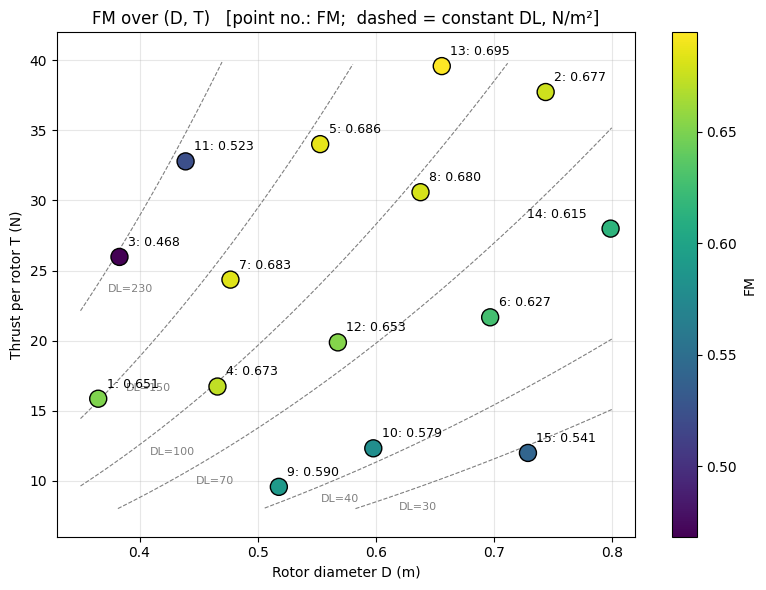

In [6]:
D_grid = np.linspace(D_min, D_max, 200)
DL_levels = np.geomspace(df.DL.min(), df.DL.max(), 6).round(-1)

fig, ax = plt.subplots(figsize=(8, 6))
for lvl in DL_levels:
    T_line = lvl * np.pi * D_grid**2 / 4
    ok = (T_line >= T_min) & (T_line <= T_max)
    if ok.any():
        ax.plot(D_grid[ok], T_line[ok], '--', color='grey', lw=0.8)
        m = np.flatnonzero(ok)[int(ok.sum() * 0.15)]      # label near the lower end of the visible segment
        ax.annotate(f'DL={lvl:.0f}', (D_grid[m], T_line[m]), fontsize=8, color='grey',
                    xytext=(4, -10), textcoords='offset points')
sc = ax.scatter(df.D_m, df.T_N, c=df.FM, s=150, cmap='viridis', edgecolor='black', zorder=3)
plt.colorbar(sc, ax=ax, label='FM')
for i, r in df.iterrows():
    dx = -60 if r.D_m > 0.75 else 6                       # keep labels inside the frame
    ax.annotate(f"{i}: {r.FM:.3f}", (r.D_m, r.T_N), textcoords='offset points', xytext=(dx, 8), fontsize=9)
ax.set_xlim(D_min - 0.02, D_max + 0.02); ax.set_ylim(T_min - 2, T_max + 2)
ax.set_xlabel('Rotor diameter D (m)'); ax.set_ylabel('Thrust per rotor T (N)')
ax.set_title('FM over (D, T)   [point no.: FM;  dashed = constant DL, N/m²]')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Observation (do high / low FM regions follow the iso-DL curves? which points stand apart from their neighbours?): _..._

## 3. FM vs disk loading
Plot FM against log(DL), coloured by D. If DL is the right variable, the points fall on one curve
and the colour (D) does not matter at a given DL.

Prediction (shape of FM vs DL: rising, falling, peaked?): _..._

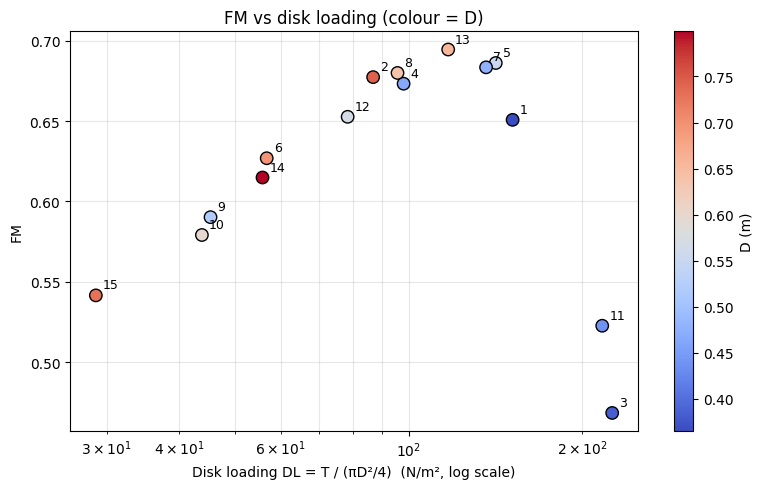

      D_m    T_N       DL     FM
pt                              
15  0.729  11.98   28.702  0.542
10  0.598  12.31   43.829  0.579
9   0.518   9.56   45.364  0.590
14  0.799  27.99   55.824  0.615
6   0.697  21.66   56.768  0.627
12  0.568  19.87   78.417  0.653
2   0.744  37.74   86.809  0.677
8   0.638  30.59   95.686  0.680
4   0.466  16.72   98.034  0.673
13  0.656  39.59  117.135  0.695
7   0.477  24.35  136.261  0.684
5   0.553  34.02  141.643  0.686
1   0.365  15.85  151.479  0.651
11  0.439  32.79  216.632  0.523
3   0.383  25.97  225.416  0.468


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(df.DL, df.FM, c=df.D_m, s=80, cmap='coolwarm', edgecolor='black', zorder=3)
for i, r in df.iterrows():
    ax.annotate(str(i), (r.DL, r.FM), textcoords='offset points', xytext=(5, 5), fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('Disk loading DL = T / (πD²/4)  (N/m², log scale)'); ax.set_ylabel('FM')
ax.set_title('FM vs disk loading (colour = D)')
plt.colorbar(sc, ax=ax, label='D (m)')
ax.grid(alpha=0.3, which='both'); plt.tight_layout(); plt.show()

print(df.sort_values('DL')[['D_m', 'T_N', 'DL', 'FM']].round(3).to_string())

Observation (one curve or scatter? smooth everywhere? at similar DL, do different D give different FM?): _..._

## 4. Does DL alone explain FM?
Compare two simple least-squares fits:
- **1-D:** quadratic in log(DL) — 3 coefficients
- **2-D:** full quadratic in scaled (D, T) — 6 coefficients

The 2-D model has more coefficients, so it always fits the training points at least as well.
The fair comparison is the **leave-one-out (LOO) RMSE**: refit without each point and predict it.
If the 1-D model's LOO RMSE is similar or lower, DL captures most of what (D, T) does.

Prediction: _..._

In [8]:
y = df.FM.values
n = len(y)
x1 = ((df.D_m - D_min) / (D_max - D_min)).values
x2 = ((df.T_N - T_min) / (T_max - T_min)).values
u  = df.logDL.values

designs = {
    'quadratic in log(DL)  (1-D)': np.column_stack([np.ones(n), u, u**2]),
    'quadratic in (D, T)   (2-D)': np.column_stack([np.ones(n), x1, x2, x1**2, x1*x2, x2**2]),
}

def fit_stats(X, y):
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    res = y - X @ beta
    h = np.diag(X @ np.linalg.pinv(X.T @ X) @ X.T)       # leverage
    loo = res / (1 - h)                                   # exact LOO residuals for least squares
    r2 = 1 - res @ res / ((y - y.mean()) @ (y - y.mean()))
    return beta, res, loo, r2

results = {}
for name, X in designs.items():
    beta, res, loo, r2 = fit_stats(X, y)
    results[name] = dict(beta=beta, res=res, loo=loo, X=X)
    print(f"{name}:  k = {X.shape[1]}   R² = {r2:.3f}   "
          f"fit RMSE = {np.sqrt(np.mean(res**2)):.4f}   LOO RMSE = {np.sqrt(np.mean(loo**2)):.4f}")
print(f"\nFor scale: std of FM = {y.std(ddof=1):.4f}")

quadratic in log(DL)  (1-D):  k = 3   R² = 0.760   fit RMSE = 0.0328   LOO RMSE = 0.0589
quadratic in (D, T)   (2-D):  k = 6   R² = 0.709   fit RMSE = 0.0360   LOO RMSE = 0.0743

For scale: std of FM = 0.0691


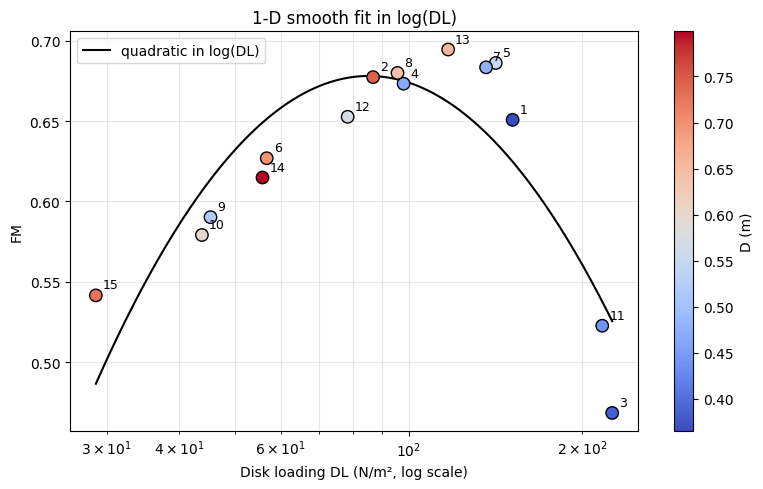

In [9]:
# 1-D fit drawn over the data
b = results['quadratic in log(DL)  (1-D)']['beta']
u_grid = np.linspace(u.min(), u.max(), 200)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.exp(u_grid), b[0] + b[1]*u_grid + b[2]*u_grid**2, 'k-', label='quadratic in log(DL)')
sc = ax.scatter(df.DL, df.FM, c=df.D_m, s=80, cmap='coolwarm', edgecolor='black', zorder=3)
for i, r in df.iterrows():
    ax.annotate(str(i), (r.DL, r.FM), textcoords='offset points', xytext=(5, 5), fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('Disk loading DL (N/m², log scale)'); ax.set_ylabel('FM')
ax.set_title('1-D smooth fit in log(DL)'); ax.legend()
plt.colorbar(sc, ax=ax, label='D (m)')
ax.grid(alpha=0.3, which='both'); plt.tight_layout(); plt.show()

Observation (which model predicts unseen points better? is DL enough, or is there a leftover D effect?): _..._

## 5. Where does a smooth model struggle? Residuals vs DL
Residuals of the 1-D fit plotted against DL (colour = D).
- A pattern along DL (e.g. a run of same-sign residuals at low or high DL) ⇒ the smooth curve misses real shape there.
- A colour trend at the same DL ⇒ D matters beyond DL.
- Studentized residual |r| > 2 ⇒ point not explained by the model (real physics or bad data?).

Prediction (where along DL do you expect the largest misfit?): _..._

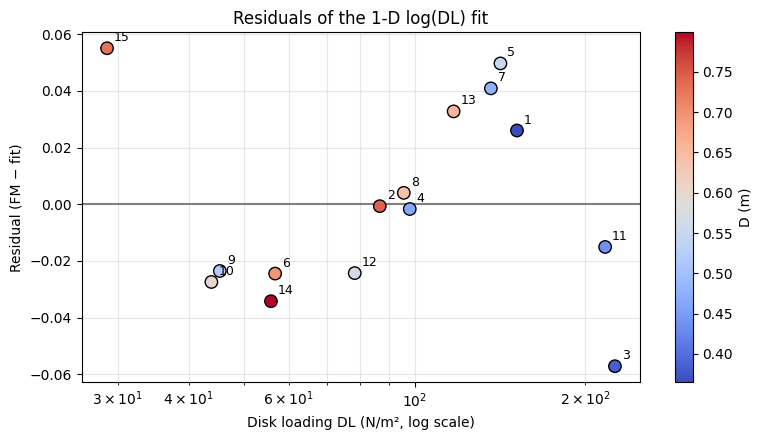

      D_m    T_N        DL      FM  resid_1D  stud_1D  loo_1D  loo_2D
pt                                                                   
15  0.729  11.98   28.7020  0.5415    0.0550   2.6464  0.1706  0.1695
10  0.598  12.31   43.8294  0.5791   -0.0274  -0.8224 -0.0331 -0.0507
9   0.518   9.56   45.3637  0.5902   -0.0235  -0.7004 -0.0280 -0.0774
14  0.799  27.99   55.8238  0.6149   -0.0342  -0.9984 -0.0391 -0.0181
6   0.697  21.66   56.7679  0.6269   -0.0245  -0.7136 -0.0279 -0.0138
12  0.568  19.87   78.4172  0.6527   -0.0243  -0.7103 -0.0279 -0.0213
2   0.744  37.74   86.8093  0.6774   -0.0007  -0.0195 -0.0008 -0.0433
8   0.638  30.59   95.6860  0.6800    0.0040   0.1173  0.0046 -0.0107
4   0.466  16.72   98.0335  0.6733   -0.0017  -0.0489 -0.0019  0.0293
13  0.656  39.59  117.1353  0.6946    0.0328   0.9484  0.0368  0.0335
7   0.477  24.35  136.2612  0.6835    0.0409   1.1821  0.0458  0.0576
5   0.553  34.02  141.6427  0.6862    0.0497   1.4391  0.0559  0.0596
1   0.365  15.85  15

In [10]:
r1 = results['quadratic in log(DL)  (1-D)']
X1 = r1['X']; k1 = X1.shape[1]
h1 = np.diag(X1 @ np.linalg.pinv(X1.T @ X1) @ X1.T)
s2 = r1['res'] @ r1['res'] / (n - k1)
df['resid_1D'] = r1['res']
df['loo_1D']   = r1['loo']
df['stud_1D']  = r1['res'] / np.sqrt(s2 * (1 - h1))
df['loo_2D']   = results['quadratic in (D, T)   (2-D)']['loo']

fig, ax = plt.subplots(figsize=(8, 4.5))
sc = ax.scatter(df.DL, df.resid_1D, c=df.D_m, s=80, cmap='coolwarm', edgecolor='black', zorder=3)
for i, r in df.iterrows():
    ax.annotate(str(i), (r.DL, r.resid_1D), textcoords='offset points', xytext=(5, 5), fontsize=9)
ax.axhline(0, color='grey')
ax.set_xscale('log'); ax.set_xlabel('Disk loading DL (N/m², log scale)'); ax.set_ylabel('Residual (FM − fit)')
ax.set_title('Residuals of the 1-D log(DL) fit')
plt.colorbar(sc, ax=ax, label='D (m)')
ax.grid(alpha=0.3, which='both'); plt.tight_layout(); plt.show()

print(df.sort_values('DL')[['D_m', 'T_N', 'DL', 'FM', 'resid_1D', 'stud_1D', 'loo_1D', 'loo_2D']]
      .round(4).to_string())
print("\nFlagged (|studentized| > 2):", list(df.index[df.stud_1D.abs() > 2]))

Observation (random cloud, or a pattern at low / high DL? which points are flagged? does D colour show a trend?): _..._

## Summary for the decision log / formulation card
1. Data validity: _..._
2. Shape of FM (does DL collapse the data? peaked / monotonic? leftover D effect?): _..._
3. Region a smooth model will handle badly (in terms of DL): _..._
4. Consequence for surrogate choice (inputs/transform, model types): _..._
5. Consequence for request 2 (where to sample, in DL and in (D, T)): _..._